# Введение в PyTorch

В этой лабораторной работе вы написали немало кода и реализовали целый набор возможностей нейронных сетей. Dropout (случайное отключение нейронов), батч-нормализация и двумерные свёртки — одни из главных рабочих инструментов глубокого обучения в компьютерном зрении. Кроме того, вы постарались сделать свой код эффективным и векторизованным.

Однако в этой части лабораторной работы мы оставим ваш замечательный код в стороне и перейдём на один из самых популярных фреймворков глубокого обучения — PyTorch.

In [1]:
# @title Настройка окружения (запустите эту ячейку первой)
# В Google Colab ячейка подключит ваш Google Диск и перейдёт в папку с лабораторной.
# При локальном запуске (Jupyter) ничего подключать не нужно: достаточно открыть
# ноутбук из папки лабораторной.

# Путь к папке лабораторной внутри «Моего диска», например 'DL/assignment2'.
# Если оставить пустым, папка будет найдена автоматически.
FOLDERNAME = ''  # @param {type:"string"}

import glob
import os
import sys

NOTEBOOK = 'PyTorch.ipynb'

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive'
    lab_dir = None
    if FOLDERNAME:
        lab_dir = os.path.join(DRIVE_ROOT, FOLDERNAME.strip('/'))
    else:
        # Ищем на Диске папку, в которой лежат этот ноутбук и пакет dlcv.
        for depth in range(5):
            pattern = os.path.join(DRIVE_ROOT, *['*'] * depth, 'dlcv', '__init__.py')
            found = [os.path.dirname(os.path.dirname(p)) for p in sorted(glob.glob(pattern))]
            found = [d for d in found if os.path.isfile(os.path.join(d, NOTEBOOK))]
            if found:
                # Если копий несколько, берём ту, где ноутбук менялся последним.
                found.sort(key=lambda d: os.path.getmtime(os.path.join(d, NOTEBOOK)),
                           reverse=True)
                lab_dir = found[0]
                if len(found) > 1:
                    print('Найдено несколько папок с лабораторной:', *found, sep='\n  ')
                    print('Используется', lab_dir, '(другую папку можно указать в FOLDERNAME)')
                break
    if lab_dir is None or not os.path.isdir(os.path.join(lab_dir, 'dlcv')):
        raise FileNotFoundError(
            'Не удалось найти папку с лабораторной на Google Диске. Укажите путь '
            'к ней в FOLDERNAME, например: FOLDERNAME = \'DL/assignment2\'')
    os.chdir(lab_dir)

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки лабораторной.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# В Colab используется IPython 7.x, и на Python 3.12+ его расширение autoreload
# не загружается: ему нужен удалённый из Python модуль imp. Подставляем
# совместимую замену (расширению нужна только функция reload).
import IPython
if (sys.version_info >= (3, 12) and IPython.version_info[0] < 8
        and 'imp' not in sys.modules):
    import importlib
    import types
    sys.modules['imp'] = types.ModuleType('imp')
    sys.modules['imp'].reload = importlib.reload

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())

Рабочая папка: assignment2 (локальный путь скрыт)


## Зачем нужны фреймворки глубокого обучения?

* Теперь наш код сможет работать на GPU! Благодаря этому модели будут обучаться гораздо быстрее. Фреймворк вроде PyTorch позволяет задействовать мощь GPU для ваших собственных архитектур нейронных сетей, не программируя напрямую на CUDA (это выходит за рамки курса).
* Умение работать с таким фреймворком пригодится в ваших собственных проектах: экспериментировать с ним гораздо эффективнее, чем писать каждую нужную функцию вручную.
* Стойте на плечах гигантов! PyTorch — отличный фреймворк, который заметно упростит вам жизнь, и теперь, когда вы понимаете, как такие фреймворки устроены изнутри, можно смело ими пользоваться :)
* Наконец, вы познакомитесь с тем, как выглядит код глубокого обучения, с которым можно столкнуться в научной работе и в индустрии.

## Что такое PyTorch?

PyTorch — это система для выполнения динамических вычислительных графов над объектами-тензорами (`Tensor`), которые ведут себя примерно так же, как массивы numpy (`ndarray`). В PyTorch есть мощный механизм автоматического дифференцирования (autograd), поэтому реализовывать обратное распространение ошибки вручную больше не нужно.

## Как изучить PyTorch?

Хорошее введение — [туториал по PyTorch с примерами](https://github.com/jcjohnson/pytorch-examples) (на английском языке).

Подробная [документация по API](http://pytorch.org/docs/stable/index.html) есть на официальном сайте. Если ответа на ваш вопрос в документации нет, задайте его на [форуме PyTorch](https://discuss.pytorch.org/) — там больше шансов получить толковый ответ, чем на StackOverflow.

# Содержание

Этот ноутбук состоит из пяти частей. Вы изучите PyTorch на **трёх разных уровнях абстракции**: это поможет лучше в нём разобраться и пригодится в ваших собственных проектах.

1. Часть I. Подготовка: загрузим набор данных CIFAR-10.
2. Часть II. PyTorch «на низком уровне» (barebones): **уровень абстракции 1** — работаем напрямую с тензорами PyTorch, самыми низкоуровневыми объектами.
3. Часть III. API `nn.Module`: **уровень абстракции 2** — с помощью `nn.Module` описываем нейронную сеть произвольной архитектуры.
4. Часть IV. API `nn.Sequential`: **уровень абстракции 3** — с помощью `nn.Sequential` очень удобно описываем сеть прямого распространения, в которой слои идут друг за другом.
5. Часть V. Свободное задание на CIFAR-10: реализуйте собственную сеть и добейтесь на CIFAR-10 как можно более высокой точности. Можно экспериментировать с любыми слоями, оптимизаторами, гиперпараметрами и другими продвинутыми приёмами.

Сравнение подходов:

| API                        | Гибкость | Удобство |
|----------------------------|----------|----------|
| PyTorch «на низком уровне» | Высокая  | Низкое   |
| `nn.Module`                | Высокая  | Среднее  |
| `nn.Sequential`            | Низкая   | Высокое  |

# GPU

На GPU нейронные сети обучаются намного быстрее, чем на CPU. Чтобы подключить GPU в Google Colab, откройте меню «Среда выполнения» → «Сменить среду выполнения» (в английском интерфейсе — `Runtime → Change runtime type`), выберите в разделе «Аппаратный ускоритель» (`Hardware accelerator`) вариант GPU (например, T4 GPU) и нажмите «Сохранить».

Лучше сделать это в самом начале, ещё до запуска ячейки «Настройка окружения»: при смене среды выполнения Colab начинает новый сеанс, и всё состояние ноутбука (импортированные модули, переменные, подключённый Google Диск) теряется. Если вы уже успели запустить какие-то ячейки, после смены среды заново запустите ячейку «Настройка окружения», а затем — ячейки ниже.

Если GPU недоступен (например, в бесплатной версии Colab закончился лимит на его использование), ноутбук будет работать и на CPU — просто обучение пойдёт заметно медленнее. Следующая ячейка выводит используемое устройство: `cuda` означает GPU, `cpu` — центральный процессор.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import sampler

import torchvision.datasets as dset
import torchvision.transforms as T

import numpy as np

USE_GPU = True
dtype = torch.float32 # Во всём ноутбуке используем тип float32.

if USE_GPU and torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

# Как часто (раз в сколько итераций) выводить потери на обучении.
print_every = 100
print('Используемое устройство:', device)
import random
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.benchmark = True
torch.set_num_threads(4)
print_every = 1000


Используемое устройство: cuda


# Часть I. Подготовка

Загрузим набор данных CIFAR-10. Скачивать его не придётся — он уже лежит в папке `dlcv/datasets`, но первый запуск ячейки всё равно может занять пару минут.

В предыдущих частях лабораторной работы загрузкой CIFAR-10, предобработкой данных и перебором мини-батчей занимался наш собственный код; в PyTorch для этого есть удобные готовые инструменты.

In [3]:
NUM_TRAIN = 49000

# Пакет torchvision.transforms содержит инструменты для предобработки данных
# и их аугментации. Здесь мы задаём преобразование, которое вычитает из
# каждого канала RGB его среднее значение и делит результат на стандартное
# отклонение этого канала; средние и стандартные отклонения заданы заранее.
transform = T.Compose([
                T.ToTensor(),
                T.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
            ])

# Для каждой части данных (train / val / test) создаём объект Dataset.
# Dataset выдаёт обучающие примеры по одному, поэтому каждый Dataset мы
# оборачиваем в DataLoader, который перебирает Dataset и формирует мини-батчи.
# Обучающую выборку CIFAR-10 делим на обучающую и валидационную части,
# передавая в DataLoader объект Sampler: он определяет, какие примеры брать
# из исходного Dataset.
cifar10_train = dset.CIFAR10('./dlcv/datasets', train=True, download=True,
                             transform=transform)
loader_train = DataLoader(cifar10_train, batch_size=64,
                          sampler=sampler.SubsetRandomSampler(range(NUM_TRAIN)))

cifar10_val = dset.CIFAR10('./dlcv/datasets', train=True, download=True,
                           transform=transform)
loader_val = DataLoader(cifar10_val, batch_size=64,
                        sampler=sampler.SubsetRandomSampler(range(NUM_TRAIN, 50000)))

cifar10_test = dset.CIFAR10('./dlcv/datasets', train=False, download=True,
                            transform=transform)
loader_test = DataLoader(cifar10_test, batch_size=64)

# Часть II. PyTorch «на низком уровне» (barebones)

В PyTorch есть высокоуровневые API, позволяющие удобно описывать архитектуры моделей; мы рассмотрим их в частях III и IV. А в этой части начнём с низкоуровневых элементов PyTorch, чтобы лучше разобраться в механизме автоматического дифференцирования (autograd). После этого упражнения вы сможете по достоинству оценить высокоуровневые API.

Начнём с простой полносвязной сети с ReLU для классификации изображений CIFAR: в ней один скрытый слой (два слоя весов) и нет смещений. Прямой проход в этой реализации вычисляется операциями над тензорами PyTorch, а градиенты — с помощью autograd. Важно, чтобы вы поняли каждую строку: после этого примера вам предстоит написать более сложную версию.

Если создать тензор PyTorch с параметром `requires_grad=True`, то операции с этим тензором будут не просто вычислять значения, но и незаметно для нас строить вычислительный граф. По этому графу легко выполнить обратное распространение и вычислить градиенты итоговой функции потерь по нужным тензорам. Точнее: если `x` — тензор с `x.requires_grad == True`, то после обратного распространения `x.grad` будет другим тензором, содержащим градиент итоговой скалярной функции потерь по `x`.

### Тензоры PyTorch: функция flatten
Тензор PyTorch по своей идее похож на массив numpy: это n-мерная сетка чисел, и, как и numpy, PyTorch предоставляет множество функций для эффективной работы с тензорами. В качестве простого примера ниже приведена функция `flatten`, которая меняет форму данных изображений так, чтобы их можно было подать на вход полносвязной нейронной сети.

Напомним, что данные изображений обычно хранятся в тензоре формы N x C x H x W, где:

* N — количество примеров;
* C — количество каналов;
* H — высота промежуточной карты признаков в пикселях;
* W — ширина промежуточной карты признаков в пикселях.

Такое представление данных подходит, когда мы выполняем, например, двумерную свёртку: для неё важно, как промежуточные признаки расположены в пространстве друг относительно друга. Но когда изображение обрабатывается полносвязными аффинными слоями, каждый пример должен быть представлен одним вектором — разделять данные на каналы, строки и столбцы больше незачем. Поэтому мы применяем операцию «выпрямления» (flatten), которая собирает `C x H x W` значений каждого примера в один длинный вектор. Функция `flatten` ниже сначала определяет размер батча N, а затем возвращает «представление» (view) этих данных. Метод `view` аналогичен методу `reshape` в numpy: он меняет форму `x` на N x ??, где ?? может быть каким угодно (в данном случае это будет C x H x W, но указывать это явно не нужно).

In [4]:
def flatten(x):
    N = x.shape[0] # считываем размер батча N
    return x.view(N, -1)  # «выпрямляем» C * H * W значений каждого изображения в один вектор

def test_flatten():
    x = torch.arange(12).view(2, 1, 3, 2)
    print('До выпрямления: ', x)
    print('После выпрямления: ', flatten(x))

test_flatten()

До выпрямления:  tensor([[[[ 0,  1],
          [ 2,  3],
          [ 4,  5]]],


        [[[ 6,  7],
          [ 8,  9],
          [10, 11]]]])
После выпрямления:  tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])


### PyTorch «на низком уровне»: двухслойная сеть

Здесь определена функция `two_layer_fc`, которая выполняет прямой проход двухслойной полносвязной сети с ReLU для батча изображений. Определив прямой проход, проверим, что он работает без ошибок и выдаёт результат правильной формы: пропустим через сеть нулевые данные.

Писать код здесь не нужно, но важно прочитать и понять реализацию.

In [5]:
import torch.nn.functional as F  # полезные функции без состояния

def two_layer_fc(x, params):
    """
    Полносвязная нейронная сеть со следующей архитектурой:
    полносвязный слой -> ReLU -> полносвязный слой.
    Обратите внимание: эта функция задаёт только прямой проход;
    об обратном проходе позаботится PyTorch.

    На вход сеть получает мини-батч данных формы (N, d1, ..., dM),
    где d1 * ... * dM = D. Скрытый слой содержит H нейронов, а выходной слой
    вычисляет оценки для C классов.

    Входные данные:
    - x: тензор PyTorch формы (N, d1, ..., dM) с мини-батчем входных данных
    - params: список [w1, w2] тензоров PyTorch с весами сети;
      w1 имеет форму (D, H), w2 — форму (H, C)

    Возвращает:
    - scores: тензор PyTorch формы (N, C) с оценками классов для входных
      данных x
    """
    # сначала выпрямляем изображение
    x = flatten(x)  # форма: [batch_size, C x H x W]

    w1, w2 = params

    # Прямой проход: вычисляем предсказания с помощью операций над тензорами.
    # Поскольку у w1 и w2 задано requires_grad=True, операции с этими тензорами
    # заставят PyTorch построить вычислительный граф, что позволит вычислить
    # градиенты автоматически. Так как обратный проход мы больше не пишем
    # вручную, сохранять ссылки на промежуточные значения не нужно.
    # Вместо F.relu() можно использовать эквивалентный `.clamp(min=0)`.
    x = F.relu(x.mm(w1))
    x = x.mm(w2)
    return x


def two_layer_fc_test():
    hidden_layer_size = 42
    x = torch.zeros((64, 50), dtype=dtype)  # размер мини-батча 64, размерность признаков 50
    w1 = torch.zeros((50, hidden_layer_size), dtype=dtype)
    w2 = torch.zeros((hidden_layer_size, 10), dtype=dtype)
    scores = two_layer_fc(x, [w1, w2])
    print(scores.size())  # должно получиться [64, 10]

two_layer_fc_test()

torch.Size([64, 10])


### PyTorch «на низком уровне»: трёхслойная свёрточная сеть

Здесь вам нужно дописать функцию `three_layer_convnet`, которая выполняет прямой проход трёхслойной свёрточной сети. Как и выше, реализацию можно сразу проверить, пропустив через сеть нулевые данные. Сеть должна иметь следующую архитектуру:

1. Свёрточный слой (со смещением): `channel_1` фильтров размера `KH1 x KW1`, дополнение нулями (padding) размера 2.
2. Нелинейность ReLU.
3. Свёрточный слой (со смещением): `channel_2` фильтров размера `KH2 x KW2`, дополнение нулями размера 1.
4. Нелинейность ReLU.
5. Полносвязный слой (со смещением), вычисляющий оценки (scores) для C классов.

Обратите внимание: после полносвязного слоя **нет softmax**. Дело в том, что функция потерь перекрёстной энтропии (cross-entropy) в PyTorch сама применяет softmax, а объединение этих двух шагов делает вычисления эффективнее.

**ПОДСКАЗКА**: о свёртках см. документацию [`torch.nn.functional.conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html); обратите внимание на форму свёрточных фильтров!

In [6]:
def three_layer_convnet(x, params):
    """
    Выполняет прямой проход трёхслойной свёрточной сети с архитектурой,
    описанной выше.

    Входные данные:
    - x: тензор PyTorch формы (N, 3, H, W) с мини-батчем изображений
    - params: список тензоров PyTorch с весами и смещениями сети; должен
      содержать следующие элементы:
      - conv_w1: тензор PyTorch формы (channel_1, 3, KH1, KW1) с весами
        первого свёрточного слоя
      - conv_b1: тензор PyTorch формы (channel_1,) со смещениями первого
        свёрточного слоя
      - conv_w2: тензор PyTorch формы (channel_2, channel_1, KH2, KW2) с весами
        второго свёрточного слоя
      - conv_b2: тензор PyTorch формы (channel_2,) со смещениями второго
        свёрточного слоя
      - fc_w: тензор PyTorch с весами полносвязного слоя (какой должна быть
        его форма — определите сами)
      - fc_b: тензор PyTorch со смещениями полносвязного слоя (какой должна
        быть его форма — определите сами)

    Возвращает:
    - scores: тензор PyTorch формы (N, C) с оценками классов для x
    """
    conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b = params
    scores = None
    ################################################################################
    # TODO: Реализуйте прямой проход трёхслойной свёрточной сети.                  #
    ################################################################################

    x = F.relu(F.conv2d(x, conv_w1, conv_b1, padding=2))
    x = F.relu(F.conv2d(x, conv_w2, conv_b2, padding=1))
    scores = flatten(x).mm(fc_w) + fc_b
    ################################################################################
    #                              КОНЕЦ ВАШЕГО КОДА                               #
    ################################################################################
    return scores

Реализовав прямой проход свёрточной сети, запустите следующую ячейку, чтобы проверить свою реализацию.

Тензор `scores` должен иметь форму (64, 10).

In [7]:
def three_layer_convnet_test():
    x = torch.zeros((64, 3, 32, 32), dtype=dtype)  # размер мини-батча 64, размер изображения [3, 32, 32]

    conv_w1 = torch.zeros((6, 3, 5, 5), dtype=dtype)  # форма: [out_channel, in_channel, kernel_H, kernel_W]
    conv_b1 = torch.zeros((6,))  # форма: [out_channel]
    conv_w2 = torch.zeros((9, 6, 3, 3), dtype=dtype)  # форма: [out_channel, in_channel, kernel_H, kernel_W]
    conv_b2 = torch.zeros((9,))  # форма: [out_channel]

    # Форму тензора после двух свёрточных слоёв (перед полносвязным слоем)
    # нужно вычислять самостоятельно; здесь это 9 * 32 * 32.
    fc_w = torch.zeros((9 * 32 * 32, 10))
    fc_b = torch.zeros(10)

    scores = three_layer_convnet(x, [conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b])
    print(scores.size())  # должно получиться [64, 10]
three_layer_convnet_test()

torch.Size([64, 10])


### PyTorch «на низком уровне»: инициализация
Напишем пару вспомогательных функций для инициализации матриц весов наших моделей.

- `random_weight(shape)` инициализирует тензор весов методом Kaiming.
- `zero_weight(shape)` инициализирует тензор весов нулями. Пригодится для создания смещений.

Функция `random_weight` использует нормальную инициализацию Kaiming (её также называют инициализацией He), описанную в статье:

He et al, *Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification*, ICCV 2015, https://arxiv.org/abs/1502.01852

In [8]:
def random_weight(shape):
    """
    Создаёт случайные тензоры весов. Флаг requires_grad=True означает, что
    для этих тензоров нужно вычислять градиенты при обратном проходе.
    Используется инициализация Kaiming: стандартное отклонение sqrt(2 / fan_in).
    """
    if len(shape) == 2:  # веса полносвязного слоя
        fan_in = shape[0]
    else:
        fan_in = np.prod(shape[1:]) # веса свёрточного слоя [out_channel, in_channel, kH, kW]
    # randn генерирует числа из стандартного нормального распределения.
    w = torch.randn(shape, device=device, dtype=dtype) * np.sqrt(2. / fan_in)
    w.requires_grad = True
    return w

def zero_weight(shape):
    return torch.zeros(shape, device=device, dtype=dtype, requires_grad=True)

# Создаём веса формы [3 x 5].
# На GPU в выводе будет указано device='cuda:0' (тип torch.cuda.FloatTensor),
# на CPU устройство не указывается (тип torch.FloatTensor).
random_weight((3, 5))

tensor([[ 0.1584,  1.7648, -0.1405,  0.6933, -1.5713],
        [ 0.5332, -0.5303, -0.6675,  0.4311, -1.0413],
        [-1.3571, -0.2477, -0.0756,  0.1627, -0.9148]], device='cuda:0',
       requires_grad=True)

### PyTorch «на низком уровне»: проверка точности
Во время обучения точность модели на валидационной (или тестовой) выборке мы будем проверять с помощью следующей функции.

При проверке точности градиенты не нужны, а значит, и строить вычислительный граф при вычислении оценок PyTorch не требуется. Чтобы граф не строился, выполним вычисления внутри контекстного менеджера `torch.no_grad()`.

In [9]:
def check_accuracy_part2(loader, model_fn, params):
    """
    Проверяет точность классификационной модели.

    Входные данные:
    - loader: DataLoader для той части данных, на которой проверяется точность
    - model_fn: функция, выполняющая прямой проход модели, с сигнатурой
      scores = model_fn(x, params)
    - params: список тензоров PyTorch с параметрами модели

    Возвращает: ничего, но выводит точность модели
    """
    split = 'валидационной' if loader.dataset.train else 'тестовой'
    print('Проверка точности на %s выборке' % split)
    num_correct, num_samples = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)  # переносим на устройство, например на GPU
            y = y.to(device=device, dtype=torch.int64)
            scores = model_fn(x, params)
            _, preds = scores.max(1)
            num_correct += (preds == y).sum()
            num_samples += preds.size(0)
        acc = float(num_correct) / num_samples
        print('Верно %d из %d (%.2f%%)' % (num_correct, num_samples, 100 * acc))

### PyTorch «на низком уровне»: цикл обучения
Теперь можно написать простой цикл обучения сети. Будем обучать модель стохастическим градиентным спуском (SGD) без момента. Функцию потерь будем вычислять с помощью `torch.nn.functional.cross_entropy`; о ней можно [прочитать в документации](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html).

Цикл обучения принимает на вход функцию нейронной сети, список инициализированных параметров (в нашем примере — `[w1, w2]`) и скорость обучения.

In [10]:
def train_part2(model_fn, params, learning_rate):
    """
    Обучает модель на CIFAR-10.

    Входные данные:
    - model_fn: функция Python, выполняющая прямой проход модели. Её сигнатура:
      scores = model_fn(x, params), где x — тензор PyTorch с изображениями,
      params — список тензоров PyTorch с весами модели, а scores — тензор
      PyTorch формы (N, C) с оценками для элементов x
    - params: список тензоров PyTorch с весами модели
    - learning_rate: скаляр Python — скорость обучения для SGD

    Возвращает: ничего
    """
    for t, (x, y) in enumerate(loader_train):
        # Переносим данные на нужное устройство (GPU или CPU).
        x = x.to(device=device, dtype=dtype)
        y = y.to(device=device, dtype=torch.long)

        # Прямой проход: вычисляем оценки и потери.
        scores = model_fn(x, params)
        loss = F.cross_entropy(scores, y)

        # Обратный проход: PyTorch находит в вычислительном графе тензоры
        # с requires_grad=True, методом обратного распространения вычисляет
        # градиенты функции потерь по этим тензорам и сохраняет их в атрибуте
        # .grad каждого тензора.
        loss.backward()

        # Обновляем параметры. Распространять градиенты через само обновление
        # параметров не нужно, поэтому выполняем его внутри контекстного
        # менеджера torch.no_grad(), чтобы не строился вычислительный граф.
        with torch.no_grad():
            for w in params:
                w -= learning_rate * w.grad

                # После обратного прохода вручную обнуляем градиенты.
                w.grad.zero_()

        if t % print_every == 0:
            print('Итерация %d, потери = %.4f' % (t, loss.item()))
            check_accuracy_part2(loader_val, model_fn, params)
            print()

    # Точность модели после всей эпохи обучения.
    print('Конец эпохи')
    check_accuracy_part2(loader_val, model_fn, params)

### PyTorch «на низком уровне»: обучение двухслойной сети
Теперь всё готово для запуска цикла обучения. Тензоры весов полносвязных слоёв `w1` и `w2` нужно создать явно.

Каждый мини-батч CIFAR содержит 64 примера, поэтому форма входного тензора — `[64, 3, 32, 32]`.

После выпрямления `x` имеет форму `[64, 3 * 32 * 32]`; значит, первая размерность `w1` равна 3 * 32 * 32. Вторая размерность `w1` — это размер скрытого слоя; она же будет первой размерностью `w2`.

Наконец, выход сети — 10-мерный вектор оценок для 10 классов; применив к нему softmax, получим распределение вероятностей по классам.

Подбирать гиперпараметры не нужно, но после одной эпохи обучения точность должна получиться около 40% или выше (от запуска к запуску результат может отличаться на 2–3 процентных пункта).

In [11]:
hidden_layer_size = 4000
learning_rate = 1e-2

w1 = random_weight((3 * 32 * 32, hidden_layer_size))
w2 = random_weight((hidden_layer_size, 10))

train_part2(two_layer_fc, [w1, w2], learning_rate)

Итерация 0, потери = 3.8831
Проверка точности на валидационной выборке


Верно 118 из 1000 (11.80%)



Конец эпохи
Проверка точности на валидационной выборке


Верно 429 из 1000 (42.90%)


### PyTorch «на низком уровне»: обучение свёрточной сети

В ячейке ниже обучите на CIFAR трёхслойную свёрточную сеть, используя функции, определённые выше. Сеть должна иметь следующую архитектуру:

1. Свёрточный слой (со смещением): 32 фильтра 5x5, дополнение нулями (padding) размера 2.
2. ReLU.
3. Свёрточный слой (со смещением): 16 фильтров 3x3, дополнение нулями размера 1.
4. ReLU.
5. Полносвязный слой (со смещением), вычисляющий оценки для 10 классов.

Матрицы весов инициализируйте функцией `random_weight`, а векторы смещений — функцией `zero_weight` (обе определены выше).

Подбирать гиперпараметры не нужно, но если всё сделано правильно, после одной эпохи точность должна получиться около 42% или выше (от запуска к запуску результат может отличаться на 2–3 процентных пункта).

In [12]:
learning_rate = 3e-3

channel_1 = 32
channel_2 = 16

conv_w1 = None
conv_b1 = None
conv_w2 = None
conv_b2 = None
fc_w = None
fc_b = None

################################################################################
# TODO: Инициализируйте параметры трёхслойной свёрточной сети.                 #
################################################################################

conv_w1 = random_weight((channel_1, 3, 5, 5))
conv_b1 = zero_weight((channel_1,))
conv_w2 = random_weight((channel_2, channel_1, 3, 3))
conv_b2 = zero_weight((channel_2,))
fc_w = random_weight((channel_2 * 32 * 32, 10))
fc_b = zero_weight((10,))

#
#                              КОНЕЦ ВАШЕГО КОДА                               #
################################################################################

params = [conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b]
train_part2(three_layer_convnet, params, learning_rate)

Итерация 0, потери = 3.3208
Проверка точности на валидационной выборке


Верно 145 из 1000 (14.50%)



Конец эпохи
Проверка точности на валидационной выборке


Верно 476 из 1000 (47.60%)


# Часть III. API `nn.Module`

При работе с PyTorch «на низком уровне» все тензоры параметров приходится отслеживать вручную. Для маленьких сетей с несколькими тензорами это допустимо, но в больших сетях следить за десятками или сотнями тензоров было бы крайне неудобно, да и легко ошибиться.

API `nn.Module` позволяет описывать сети произвольной архитектуры и сам отслеживает все обучаемые параметры. В части II мы реализовали SGD самостоятельно; в PyTorch есть пакет `torch.optim`, в котором реализованы все распространённые оптимизаторы, например RMSProp, Adagrad и Adam. Он поддерживает даже приближённые методы второго порядка, такие как L-BFGS! Точное описание каждого оптимизатора можно найти в [документации](https://pytorch.org/docs/stable/optim.html).

Чтобы воспользоваться API `nn.Module`, выполните следующие шаги:

1. Создайте подкласс `nn.Module`. Дайте классу сети понятное имя, например `TwoLayerFC`.

2. В конструкторе `__init__()` определите все нужные слои как атрибуты класса. Объекты слоёв, такие как `nn.Linear` и `nn.Conv2d`, сами являются подклассами `nn.Module` и содержат обучаемые параметры, так что создавать «сырые» тензоры самостоятельно не нужно: `nn.Module` будет отслеживать эти внутренние параметры за вас. О десятках встроенных слоёв можно прочитать в [документации](https://pytorch.org/docs/stable/nn.html). **Внимание**: не забудьте первым делом вызвать `super().__init__()`!

3. В методе `forward()` опишите, *как соединены* слои сети. Используйте атрибуты, определённые в `__init__`, как функции, которые принимают на вход тензор и возвращают «преобразованный» тензор. *Не* создавайте в `forward()` новых слоёв с обучаемыми параметрами! Все они должны быть заранее объявлены в `__init__`.

Определив подкласс `nn.Module`, можно создать его экземпляр и вызывать его так же, как функцию прямого прохода из части II.

### API `nn.Module`: двухслойная сеть
Вот конкретный пример двухслойной полносвязной сети:

In [13]:
class TwoLayerFC(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super().__init__()
        # объекты слоёв сохраняем в атрибутах класса
        self.fc1 = nn.Linear(input_size, hidden_size)
        # в пакете nn.init есть удобные методы инициализации
        # https://pytorch.org/docs/stable/nn.init.html
        nn.init.kaiming_normal_(self.fc1.weight)
        self.fc2 = nn.Linear(hidden_size, num_classes)
        nn.init.kaiming_normal_(self.fc2.weight)

    def forward(self, x):
        # forward всегда задаёт, как соединены слои
        x = flatten(x)
        scores = self.fc2(F.relu(self.fc1(x)))
        return scores

def test_TwoLayerFC():
    input_size = 50
    x = torch.zeros((64, input_size), dtype=dtype)  # размер мини-батча 64, размерность признаков 50
    model = TwoLayerFC(input_size, 42, 10)
    scores = model(x)
    print(scores.size())  # должно получиться [64, 10]
test_TwoLayerFC()

torch.Size([64, 10])


### API `nn.Module`: трёхслойная свёрточная сеть
Теперь ваша очередь: реализуйте трёхслойную свёрточную сеть — два свёрточных слоя и полносвязный слой. Архитектура сети должна быть такой же, как в части II:

1. Свёрточный слой: `channel_1` фильтров 5x5, дополнение нулями (padding) размера 2.
2. ReLU.
3. Свёрточный слой: `channel_2` фильтров 3x3, дополнение нулями размера 1.
4. ReLU.
5. Полносвязный слой, выдающий оценки для `num_classes` классов.

Матрицы весов модели инициализируйте нормальной инициализацией Kaiming (Kaiming normal).

**ПОДСКАЗКА**: см. документацию [`nn.Conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).

Когда реализуете сеть, функция `test_ThreeLayerConvNet` запустит вашу реализацию; форма выходных оценок должна получиться `(64, 10)`.

In [14]:
class ThreeLayerConvNet(nn.Module):
    def __init__(self, in_channel, channel_1, channel_2, num_classes):
        super().__init__()
        ########################################################################
        # TODO: Создайте слои, необходимые для трёхслойной свёрточной сети     #
        # с описанной выше архитектурой.                                       #
        ########################################################################

        self.conv1 = nn.Conv2d(in_channel, channel_1, 5, padding=2)
        self.conv2 = nn.Conv2d(channel_1, channel_2, 3, padding=1)
        self.fc = nn.Linear(channel_2 * 32 * 32, num_classes)
        for layer in (self.conv1, self.conv2, self.fc):
            nn.init.kaiming_normal_(layer.weight)
            nn.init.zeros_(layer.bias)
        ########################################################################
        #                          КОНЕЦ ВАШЕГО КОДА                           #
        ########################################################################

    def forward(self, x):
        scores = None
        ########################################################################
        # TODO: Реализуйте метод forward трёхслойной свёрточной сети.          #
        # Используйте слои, определённые в __init__, и задайте в forward()     #
        # связи между ними.                                                    #
        ########################################################################

        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        scores = self.fc(flatten(x))
        ########################################################################
        #                          КОНЕЦ ВАШЕГО КОДА                           #
        ########################################################################
        return scores


def test_ThreeLayerConvNet():
    x = torch.zeros((64, 3, 32, 32), dtype=dtype)  # размер мини-батча 64, размер изображения [3, 32, 32]
    model = ThreeLayerConvNet(in_channel=3, channel_1=12, channel_2=8, num_classes=10)
    scores = model(x)
    print(scores.size())  # должно получиться [64, 10]
test_ThreeLayerConvNet()

torch.Size([64, 10])


### API `nn.Module`: проверка точности
Следующая функция проверяет точность классификации нейронной сети на валидационной или тестовой выборке.

Эта версия немного отличается от версии из части II: параметры больше не нужно передавать вручную.

In [6]:
def check_accuracy_part34(loader, model):
    if loader.dataset.train:
        print('Проверка точности на валидационной выборке')
    else:
        print('Проверка точности на тестовой выборке')
    num_correct = 0
    num_samples = 0
    model.eval()  # переводим модель в режим тестирования (eval)
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)  # переносим на устройство, например на GPU
            y = y.to(device=device, dtype=torch.long)
            scores = model(x)
            _, preds = scores.max(1)
            num_correct += (preds == y).sum()
            num_samples += preds.size(0)
        acc = float(num_correct) / num_samples
        print('Верно %d из %d (%.2f%%)' % (num_correct, num_samples, 100 * acc))

### API `nn.Module`: цикл обучения
Цикл обучения тоже будет немного другим. Вместо того чтобы обновлять значения весов самостоятельно, воспользуемся объектом-оптимизатором (`Optimizer`) из пакета `torch.optim`. Он инкапсулирует алгоритм оптимизации, а в самом пакете реализовано большинство алгоритмов, которые обычно применяются для оптимизации нейронных сетей.

In [16]:
def train_part34(model, optimizer, epochs=1, scheduler=None):
    """
    Обучает модель на CIFAR-10 с помощью API nn.Module.

    Входные данные:
    - model: модуль PyTorch (nn.Module) — модель, которую нужно обучить
    - optimizer: объект Optimizer, с помощью которого обучается модель
    - epochs: (необязательный) целое число Python — количество эпох обучения
    - scheduler: (необязательный) расписание скорости обучения из
      torch.optim.lr_scheduler; его шаг выполняется после каждого шага
      оптимизатора

    Возвращает: ничего, но во время обучения выводит точность модели
    """
    model = model.to(device=device)  # переносим параметры модели на CPU/GPU
    for e in range(epochs):
        for t, (x, y) in enumerate(loader_train):
            model.train()  # переводим модель в режим обучения
            x = x.to(device=device, dtype=dtype)  # переносим на устройство, например на GPU
            y = y.to(device=device, dtype=torch.long)

            scores = model(x)
            loss = F.cross_entropy(scores, y)

            # Обнуляем градиенты всех переменных, которые будет обновлять
            # оптимизатор.
            optimizer.zero_grad()

            # Обратный проход: вычисляем градиент функции потерь по каждому
            # параметру модели.
            loss.backward()

            # Обновляем параметры модели с помощью градиентов, вычисленных
            # при обратном проходе.
            optimizer.step()
            if scheduler is not None:
                scheduler.step()

            if t % print_every == 0:
                print('Итерация %d, потери = %.4f' % (t, loss.item()))
                check_accuracy_part34(loader_val, model)
                print()

        # Точность модели после всей эпохи обучения.
        print('Конец эпохи %d' % (e + 1))
        check_accuracy_part34(loader_val, model)
        print()

### API `nn.Module`: обучение двухслойной сети
Теперь можно запустить цикл обучения. В отличие от части II, тензоры параметров больше не нужно создавать явно.

Достаточно передать в конструктор `TwoLayerFC` размер входа, размер скрытого слоя и количество классов (то есть размер выхода).

Также нужно создать оптимизатор, который отслеживает все обучаемые параметры внутри `TwoLayerFC`.

Подбирать гиперпараметры не нужно, но после одной эпохи обучения точность модели должна получиться около 40% или выше (от запуска к запуску результат может отличаться на 2–3 процентных пункта).

In [17]:
hidden_layer_size = 4000
learning_rate = 1e-2
model = TwoLayerFC(3 * 32 * 32, hidden_layer_size, 10)
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

train_part34(model, optimizer)

Итерация 0, потери = 3.4975
Проверка точности на валидационной выборке


Верно 154 из 1000 (15.40%)



Конец эпохи 1
Проверка точности на валидационной выборке


Верно 434 из 1000 (43.40%)



### API `nn.Module`: обучение трёхслойной свёрточной сети
Теперь с помощью API `nn.Module` обучите на CIFAR трёхслойную свёрточную сеть. Код будет очень похож на обучение двухслойной сети! Подбирать гиперпараметры не нужно, но после одной эпохи обучения точность должна получиться около 45% или выше (от запуска к запуску результат может отличаться на 2–3 процентных пункта).

Обучайте модель стохастическим градиентным спуском без момента.

In [18]:
learning_rate = 3e-3
channel_1 = 32
channel_2 = 16

model = None
optimizer = None
################################################################################
# TODO: Создайте модель ThreeLayerConvNet и соответствующий оптимизатор.       #
################################################################################

model = ThreeLayerConvNet(3, channel_1, channel_2, 10).to(device)
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

#
#                              КОНЕЦ ВАШЕГО КОДА                               #
################################################################################

train_part34(model, optimizer)

Итерация 0, потери = 2.9681
Проверка точности на валидационной выборке


Верно 126 из 1000 (12.60%)



Конец эпохи 1
Проверка точности на валидационной выборке


Верно 497 из 1000 (49.70%)



# Часть IV. API `nn.Sequential`

В части III мы познакомились с API `nn.Module`, который позволяет описывать произвольные обучаемые слои и связи между ними.

Но даже для простых моделей, например для последовательности слоёв прямого распространения, по-прежнему приходится выполнять три шага: создать подкласс `nn.Module`, присвоить слои атрибутам класса в `__init__` и по очереди вызвать каждый слой в `forward()`. Нельзя ли проще?

К счастью, в PyTorch есть модуль-контейнер `nn.Sequential`, который объединяет эти шаги в один. Он не такой гибкий, как `nn.Module`: описать с его помощью топологию сложнее простой последовательности слоёв не получится. Но для многих задач его вполне достаточно.

### API `nn.Sequential`: двухслойная сеть
Посмотрим, как переписать пример с двухслойной полносвязной сетью с помощью `nn.Sequential` и обучить её с помощью цикла обучения, определённого выше.

Подбирать гиперпараметры снова не нужно, но после одной эпохи обучения точность должна получиться около 40% или выше (от запуска к запуску результат может отличаться на 2–3 процентных пункта).

In [19]:
# Чтобы использовать функцию `flatten` внутри nn.Sequential, её нужно
# обернуть в модуль.
class Flatten(nn.Module):
    def forward(self, x):
        return flatten(x)

hidden_layer_size = 4000
learning_rate = 1e-2

model = nn.Sequential(
    Flatten(),
    nn.Linear(3 * 32 * 32, hidden_layer_size),
    nn.ReLU(),
    nn.Linear(hidden_layer_size, 10),
)

# в optim.SGD можно использовать момент Нестерова
optimizer = optim.SGD(model.parameters(), lr=learning_rate,
                     momentum=0.9, nesterov=True)

train_part34(model, optimizer)

Итерация 0, потери = 2.3850
Проверка точности на валидационной выборке


Верно 156 из 1000 (15.60%)



Конец эпохи 1
Проверка точности на валидационной выборке


Верно 438 из 1000 (43.80%)



### API `nn.Sequential`: трёхслойная свёрточная сеть
Теперь с помощью `nn.Sequential` опишите и обучите трёхслойную свёрточную сеть с той же архитектурой, что и в части III:

1. Свёрточный слой (со смещением): 32 фильтра 5x5, дополнение нулями (padding) размера 2.
2. ReLU.
3. Свёрточный слой (со смещением): 16 фильтров 3x3, дополнение нулями размера 1.
4. ReLU.
5. Полносвязный слой (со смещением), вычисляющий оценки для 10 классов.

Можно использовать инициализацию весов PyTorch по умолчанию.

Оптимизируйте модель стохастическим градиентным спуском с моментом Нестерова 0.9.

Подбирать гиперпараметры снова не нужно, но после одной эпохи обучения точность должна получиться около 55% или выше (от запуска к запуску результат может отличаться на 2–3 процентных пункта).

In [20]:
channel_1 = 32
channel_2 = 16
learning_rate = 1e-2

model = None
optimizer = None

################################################################################
# TODO: Перепишите трёхслойную свёрточную сеть (со смещениями) из части III    #
# с помощью API nn.Sequential.                                                 #
################################################################################

model = nn.Sequential(
    nn.Conv2d(3, channel_1, 5, padding=2), nn.ReLU(),
    nn.Conv2d(channel_1, channel_2, 3, padding=1), nn.ReLU(),
    Flatten(), nn.Linear(channel_2 * 32 * 32, 10),
).to(device)
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9, nesterov=True)

#
#                              КОНЕЦ ВАШЕГО КОДА                               #
################################################################################

train_part34(model, optimizer)

Итерация 0, потери = 2.3288
Проверка точности на валидационной выборке


Верно 130 из 1000 (13.00%)



Конец эпохи 1
Проверка точности на валидационной выборке


Верно 587 из 1000 (58.70%)



# Часть V. Свободное задание на CIFAR-10

В этой части вы можете экспериментировать на CIFAR-10 с любой архитектурой свёрточной сети.

Ваша задача — подобрать архитектуру, гиперпараметры, функцию потерь и оптимизатор так, чтобы модель достигала точности **не менее 70%** на **валидационной** выборке CIFAR-10 не более чем за 10 эпох обучения. Можно использовать функции `check_accuracy_part34` и `train_part34`, определённые выше, и любой из двух API: `nn.Module` или `nn.Sequential`. Расписание скорости обучения (`torch.optim.lr_scheduler`) можно передать в `train_part34` через аргумент `scheduler`. Для аугментации данных создайте заново `loader_train` с другим преобразованием (`transform`): `train_part34` берёт мини-батчи именно из этой переменной.

В конце ноутбука опишите, что вы сделали.

Ниже приведены ссылки на официальную документацию по каждому компоненту. Одно замечание: то, что в этой лабораторной работе называлось пространственной батч-нормализацией (spatial batch normalization), в PyTorch называется `BatchNorm2d`.

* Слои из пакета `torch.nn`: http://pytorch.org/docs/stable/nn.html
* Функции активации: https://pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity
* Функции потерь: http://pytorch.org/docs/stable/nn.html#loss-functions
* Оптимизаторы: http://pytorch.org/docs/stable/optim.html


### Что можно попробовать
- **Размер фильтров**: выше мы использовали фильтры 5x5; будут ли фильтры меньшего размера эффективнее?
- **Количество фильтров**: выше мы использовали 32 фильтра. Как лучше — больше или меньше?
- **Пулинг или свёртка с шагом**: что использовать — max-пулинг или просто свёртки с шагом (stride)?
- **Батч-нормализация**: попробуйте добавить пространственную батч-нормализацию после свёрточных слоёв и обычную батч-нормализацию после аффинных слоёв. Быстрее ли обучаются сети?
- **Архитектура сети**: у сетей выше всего два-три слоя с обучаемыми параметрами. Получится ли лучше с более глубокой сетью? Вот хорошие архитектуры, которые стоит попробовать:
    - [conv-relu-pool]xN -> [affine]xM -> [softmax или SVM]
    - [conv-relu-conv-relu-pool]xN -> [affine]xM -> [softmax или SVM]
    - [batchnorm-relu-conv]xN -> [affine]xM -> [softmax или SVM]
- **Глобальный усредняющий пулинг (global average pooling)**: вместо того чтобы выпрямлять тензор и применять несколько аффинных слоёв, выполняйте свёртки, пока изображение не станет маленьким (порядка 7x7), а затем примените усредняющий пулинг и получите «изображение» 1x1 формы (1, 1, F), где F — количество фильтров; затем оно преобразуется в вектор длины F. Такой приём используется в [сети Inception от Google](https://arxiv.org/abs/1512.00567) (её архитектура приведена в таблице 1 статьи).
- **Регуляризация**: добавьте L2-регуляризацию весов или, например, dropout.

### Советы по обучению
Для каждой архитектуры, которую вы пробуете, подбирайте скорость обучения и другие гиперпараметры. При этом важно помнить о нескольких вещах:

- Если параметры подобраны удачно, улучшение должно быть заметно уже через несколько сотен итераций.
- Вспомните подход «от грубого к точному» (coarse-to-fine) к подбору гиперпараметров: сначала проверьте широкий диапазон гиперпараметров, обучая модель всего несколько итераций, чтобы найти комбинации, которые вообще работают.
- Найдя наборы параметров, которые, по-видимому, работают, ищите точнее в их окрестности. Возможно, обучать придётся больше эпох.
- Для подбора гиперпараметров используйте валидационную выборку, а тестовую приберегите для итоговой оценки архитектуры с лучшими параметрами, выбранными по валидационной выборке.

### Если хочется большего
Если вы готовы к приключениям, есть много других приёмов, которые можно реализовать, чтобы улучшить результат. Делать это **не обязательно**, но если есть время — попробуйте: это интересно!

- Другие оптимизаторы: можно попробовать Adam, Adagrad, RMSprop и т. д.
- Другие функции активации: leaky ReLU, parametric ReLU, ELU или MaxOut.
- Ансамбли моделей.
- Аугментация данных.
- Новые архитектуры:
  - [ResNet](https://arxiv.org/abs/1512.03385): вход блока прибавляется к его выходу;
  - [DenseNet](https://arxiv.org/abs/1608.06993): каждый слой получает на вход конкатенацию выходов всех предыдущих слоёв;
  - [подробный обзор в блоге](https://chatbotslife.com/resnets-highwaynets-and-densenets-oh-my-9bb15918ee32) (на английском языке).

### Удачи и приятного обучения!

Final CNN training device: cuda


Epoch 1/10: loss=1.3255, val=55.5%


Epoch 2/10: loss=0.9436, val=66.6%


Epoch 3/10: loss=0.7923, val=71.9%


Epoch 4/10: loss=0.6970, val=73.9%


Epoch 5/10: loss=0.6237, val=75.0%


Epoch 6/10: loss=0.5687, val=79.7%


Epoch 7/10: loss=0.5250, val=82.8%


Epoch 8/10: loss=0.4878, val=83.2%


Epoch 9/10: loss=0.4671, val=83.9%


Epoch 10/10: loss=0.4574, val=83.9%


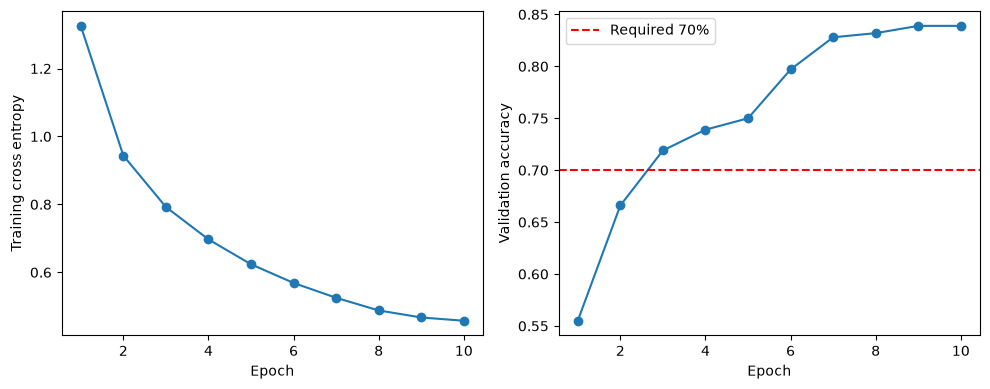

Best validation accuracy: 83.9%


In [7]:
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Final CNN training device:", device)
# Собственная CNN; тестовая выборка не участвует в выборе модели.
import copy
import matplotlib.pyplot as plt
augmentation = T.Compose([
    T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
    T.ToTensor(), T.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])
augmented_train = dset.CIFAR10('./dlcv/datasets', train=True, download=False,
                             transform=augmentation)
loader_train = DataLoader(augmented_train, batch_size=128,
    sampler=sampler.SubsetRandomSampler(range(NUM_TRAIN)), num_workers=0)

blocks = []
in_channels = 3
for channels in (32, 64, 128):
    for _ in range(2):
        blocks += [nn.Conv2d(in_channels, channels, 3, padding=1, bias=False),
                   nn.BatchNorm2d(channels), nn.ReLU(inplace=True)]
        in_channels = channels
    blocks += [nn.MaxPool2d(2)]
model = nn.Sequential(*blocks, nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                      nn.Dropout(0.2), nn.Linear(128, 10)).to(device)
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0005)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10 * len(loader_train))
history = {'loss': [], 'val_accuracy': []}
best_val = -1
best_state = None
for epoch in range(10):
    model.train()
    total_loss = 0.0
    for x, y in loader_train:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * len(x)
    model.eval()
    correct = count = 0
    with torch.no_grad():
        for x, y in loader_val:
            predictions = model(x.to(device)).argmax(1).cpu()
            correct += (predictions == y).sum().item()
            count += len(y)
    val_accuracy = correct / count
    history['loss'].append(total_loss / NUM_TRAIN)
    history['val_accuracy'].append(val_accuracy)
    if val_accuracy > best_val:
        best_val = val_accuracy
        best_state = copy.deepcopy(model.state_dict())
    print(f'Epoch {epoch+1}/10: loss={history["loss"][-1]:.4f}, val={val_accuracy:.1%}', flush=True)
model.load_state_dict(best_state)
assert best_val >= 0.70, f'Validation accuracy {best_val:.1%} is below 70%'
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(range(1, 11), history['loss'], marker='o')
axes[0].set(xlabel='Epoch', ylabel='Training cross entropy')
axes[1].plot(range(1, 11), history['val_accuracy'], marker='o')
axes[1].axhline(0.70, color='r', linestyle='--', label='Required 70%')
axes[1].set(xlabel='Epoch', ylabel='Validation accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()
print(f'Best validation accuracy: {best_val:.1%}')

torch.save(model.state_dict(), "best_cifar10_cnn.pt")


## Опишите, что вы сделали

В ячейке ниже опишите, что вы сделали: какие дополнительные возможности реализовали и/или какие графики построили в процессе обучения и оценки сети.

**Ваш ответ:** Использована сеть из трёх блоков с 32, 64 и 128 каналами. В каждом блоке две свёртки 3×3 с BatchNorm и ReLU, затем max-pooling 2×2. После глобального усреднения идут dropout 0.2 и линейный классификатор. Сеть обучена с нуля за 10 эпох AdamW (lr=0.001, weight_decay=0.0005), скорость обучения плавно уменьшается косинусным расписанием. Обучающие изображения случайно отражаются и обрезаются с padding=4; валидация и тест не аугментируются. Используются первые 49 000 изображений для обучения и последние 1 000 для валидации. Сохраняется состояние лучшей эпохи по валидации. Графики показывают обучение и валидацию; точные измеренные результаты сохранены в выводах. Тестовая выборка оценивается один раз после выбора модели.

**Измеренный результат:** Лучшая validation: 83.9%; test: 83.98% (8398/10000). Обучение с нуля за 10 эпох. Порог 70% достигнут уже на третьей эпохе (71.9%). Веса лучшей эпохи выбраны по validation; test использован единственный раз после обучения.

## Тестовая выборка — запустите только один раз

Когда результат вас устроит, проверьте итоговую модель на тестовой выборке (ячейка ниже сохраняет модель из переменной `model` в `best_model`). Подумайте, как полученная точность соотносится с точностью на валидационной выборке.

In [8]:
best_model = model
check_accuracy_part34(loader_test, best_model)

Проверка точности на тестовой выборке


Верно 8398 из 10000 (83.98%)
